# Preprocessing Teks

## Library

In [ ]:
# %pip install pandas nltk Sastrawi wordcloud matplotlib

In [ ]:
import re
import html
import polars as pl
import nltk
import numpy as np
# import spacy
import unicodedata
from functools import lru_cache
from collections import Counter
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
# import pandas as pd

from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

In [102]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.3 MB 670.4 kB/s eta 0:00:12
   -- ------------------------------------- 0.5/8.3 MB 670.4 kB/s eta 0:00:12
   --- ------------------------------------ 0.8/8.3 MB 699.0 kB/s eta 0:00:11
   --- ------------------------------------ 0.8/8.3 MB 699.0 kB/s eta 0:00:11
   ----- ---------------------------------- 1.0/8.3 MB 708.5 kB/s eta 0:00:11
   ----- ---------------------------------- 1.0/8.3 MB 708.5 kB/s eta 0:00:11
   ------ --------------------------------- 1.3/8.3 MB 706.1 kB/s eta 0:00:10
   ------- -------------------------------- 1.6/8.3 MB 710.8 kB/s eta 0:00:10
   ------- -------------------------------- 1.6/8.3 MB 710.8 kB/s eta 0:00:10
   -------- ----------

In [103]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

In [57]:
nltk.download("stopwords")

# Model spaCy untuk bahasa Indonesia
# spacy.cli.download("xx_ent_wiki_sm")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Musa\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

## Helper Fungsion

In [58]:
def to_list(v):
    """map_elements memberi pl.Series untuk kolom list -> ubah ke list Python."""
    if v is None: return []
    if isinstance(v, pl.Series): return v.to_list()
    return list(v)
 
def _apply_str(df, col, out, fn):
    return df.with_columns(pl.col(col).map_elements(fn, return_dtype=pl.Utf8).alias(out))
 
def _apply_list(df, col, out, fn):
    return df.with_columns(
        pl.col(col).map_elements(lambda v: fn(to_list(v)), return_dtype=pl.List(pl.Utf8)).alias(out))

## Dataset

In [59]:
df = pl.read_csv("data_twiter/politik.csv")

In [60]:
df

type,id,url,twitterUrl,text,source,retweetCount,replyCount,likeCount,quoteCount,viewCount,createdAt,lang,bookmarkCount,isReply,inReplyToId,conversationId,inReplyToUserId,inReplyToUsername,isPinned,author,extendedEntities,card,place,entities,reply_to_user_results,quoted_tweet_results,quoted_tweet,retweeted_tweet,isConversationControlled,searchTermIndex,isQuote
str,i64,str,str,str,str,i64,i64,i64,i64,i64,str,str,i64,bool,i64,i64,i64,str,bool,str,str,str,str,str,str,str,str,str,bool,i64,bool
"""tweet""",2108447840284668323,"""https://x.com/Jezaelans/status…","""https://twitter.com/Jezaelans/…","""@MenteriPekerja Mknya dr awal …",null,0,0,0,0,1,"""Fri Oct 09 06:41:52 +0000 2026""","""in""",0,true,2108337734675017861,2108337734675017861,1717188745227862016,"""MenteriPekerja""",false,"""{'type': 'user', 'userName': '…","""{}""",null,"""{}""","""{'user_mentions': [{'id_str': …","""{'rest_id': '17171887452278620…",null,null,null,false,0,null
"""tweet""",2108446988073402729,"""https://x.com/rang_simabua/sta…","""https://twitter.com/rang_simab…","""Pernyataan Rocky Gerung yang m…",null,2,0,2,0,30,"""Fri Oct 09 06:38:29 +0000 2026""","""in""",0,false,null,2108446988073402729,null,null,false,"""{'type': 'user', 'userName': '…","""{}""",null,"""{}""","""{'hashtags': [], 'symbols': []…",null,"""{'rest_id': '21081447174480077…","""{'type': 'tweet', 'id': '21081…",null,false,0,true
"""tweet""",2108446836512141677,"""https://x.com/BiLLRaY2019/stat…","""https://twitter.com/BiLLRaY201…","""Wantimpres angkat bicara..! R…",null,0,0,0,0,46,"""Fri Oct 09 06:37:53 +0000 2026""","""in""",0,false,null,2108446836512141677,null,null,false,"""{'type': 'user', 'userName': '…","""{'media': [{'additional_media_…",null,"""{}""","""{}""",null,null,null,null,false,0,null
"""tweet""",2108445787856458122,"""https://x.com/triwahyuutama15/…","""https://twitter.com/triwahyuut…","""Pembentukan Wantimpres oleh Pr…",null,0,0,0,0,5,"""Fri Oct 09 06:33:43 +0000 2026""","""in""",0,false,null,2108445787856458122,null,null,false,"""{'type': 'user', 'userName': '…","""{}""",null,"""{}""","""{}""",null,null,null,null,false,0,null
"""tweet""",2108445386075721812,"""https://x.com/Putra_Riau11/sta…","""https://twitter.com/Putra_Riau…","""Ternyata 1 orang seperti anda …",null,0,0,0,0,4,"""Fri Oct 09 06:32:07 +0000 2026""","""in""",0,false,null,2108445386075721812,null,null,false,"""{'type': 'user', 'userName': '…","""{'media': [{'additional_media_…",null,"""{}""","""{}""",null,null,null,null,false,0,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""tweet""",2108179303100002598,"""https://x.com/kodam_siliwangi/…","""https://twitter.com/kodam_sili…","""Kasdam III/Siliwangi Brigjen T…",null,0,0,0,0,98,"""Thu Oct 08 12:54:48 +0000 2026""","""in""",0,false,null,2108179303100002598,null,null,false,"""{'type': 'user', 'userName': '…","""{'media': [{'allow_download_st…",null,"""{}""","""{}""",null,null,null,null,false,1,null
"""tweet""",2108178863297859718,"""https://x.com/kkpgoid/status/2…","""https://twitter.com/kkpgoid/st…","""Menteri Trenggono @saktitrengg…",null,0,0,0,0,111,"""Thu Oct 08 12:53:03 +0000 2026""","""in""",0,true,2108178427111211244,2108178427111211244,2493957026,"""kkpgoid""",false,"""{'type': 'user', 'userName': '…","""{}""",null,"""{}""","""{'hashtags': [{'indices': [220…","""{'rest_id': '2493957026', 'res…",null,null,null,false,1,null
"""tweet""",2108178461231874433,"""https://x.com/BpsipSulut/statu…","""https://twitter.com/BpsipSulut…","""BRMP Sulut Dampingi Koperasi U…",null,0,0,0,0,13,"""Thu Oct 08 12:51:27 +0000 2026""","""in""",0,false,null,2108178461231874433,null,null,false,"""{'type': 'user', 'userName': '…","""{'media': [{'display_url': 'pi…",null,"""{}""","""{'urls': [{'display_url': 'fac…",null,null,null,null,false,1,null


In [61]:
df = df.select("text")
df

text
str
"""@MenteriPekerja Mknya dr awal …"
"""Pernyataan Rocky Gerung yang m…"
"""Wantimpres angkat bicara..! R…"
"""Pembentukan Wantimpres oleh Pr…"
"""Ternyata 1 orang seperti anda …"
…
"""Kasdam III/Siliwangi Brigjen T…"
"""Menteri Trenggono @saktitrengg…"
"""BRMP Sulut Dampingi Koperasi U…"


In [62]:
df.dtypes

[String]

## Noise Removal

Noise Removal digunakan untuk membersihkan atau menghapus elemen yang biasanya tidak dibutuhkan dalam analisis teks, seperti HTML, URL, alamat email, mention, karakter kontrol, dan spasi berlebih yang tidak relevan dan tidak memiliki nilai informasi untuk analisis teks.

Contoh yang dibersihkan: Tanda baca, emoji, tag HTML, URL, karakter khusus (seperti @, #, $), dan spasi berlebih (whitespace).

### Code

In [63]:
EMOJI = re.compile("[\U0001F300-\U0001FAFF\U00002600-\U000027BF\U0001F1E6-\U0001F1FF\uFE0F\u200d]")

In [ ]:
# def noise_removal(df, text_col, output_col="text_clean"):
#     def clean(text):
#         if text is None: return ""
#         text = html.unescape(str(text)) # Ubah entity dari HTML
#         text = re.sub(r"<[^>]+>", " ", text) # Menghapus Tags HTML
#         text = re.sub(r"https?://\S+|www\.\S+|\b\w+\.(?:co|com|id)/\S+", " ", text) # Hapus URL
#         text = re.sub(r"\b[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}\b", " ", text) # Alamar email
#         text = re.sub(r"(?<!\w)@\w+", " ", text) # Hapus mentions
#         text = re.sub(r"^\s*RT\b", " ", text) # Hapus RT
#         # hashtag: buang '#', pisahkan CamelCase
#         text = re.sub(r"#(\w+)", lambda m: " " + re.sub(r"(?<=[a-z])(?=[A-Z])", " ", m.group(1)) + " ", text)
#         text = EMOJI.sub(" ", text) # Emoji
#         text = re.sub(r"[\x00-\x1f\x7f]", " ", text) #ASCI
#         return re.sub(r"\s+", " ", text).strip()
#     return _apply_str(df, text_col, output_col, clean)
 
# ROMAN = re.compile(r"^m{0,3}(cm|cd|d?c{0,3})(xc|xl|l?x{0,3})(ix|iv|v?i{0,3})$")
# def _collapse(m):
#     w = m.group(0)
#     if ROMAN.match(w) or w == "www":      # III, XXX, www jangan diubah
#         return w
#     return re.sub(r"(\w)\1{2,}", r"\1", w)

### Code 2 

In [177]:
DOMAIN = re.compile(r"\b[\w-]+(?:\.[\w-]+)*\.(?:com|co\.id|go\.id|or\.id|id|net|org|my|tv|news|info)\b(?:/\S*)?", re.I)

In [178]:
def noise_removal(df, text_col, output_col="text_clean"):
    def clean(text):
        if text is None: return ""
        text = html.unescape(str(text))
        text = re.sub(r"<[^>]+>", " ", text)
        text = re.sub(r"https?://\S+|www\.\S+", " ", text)
        text = DOMAIN.sub(" ", text)                                             # suaramerdeka.com/..., domain tanpa http
        text = re.sub(r"\b[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}\b", " ", text)
        text = re.sub(r"(?<!\w)@\w+", " ", text)
        text = re.sub(r"^\s*RT\b", " ", text)
        text = re.sub(r"\b\d{4}-\d{2}-\d{2}t?[\d:.]*\b", " ", text, flags=re.I)  # 2026-10-08T13:43
        text = re.sub(r"\b\d{8,}\b", " ", text)                                  # ID panjang
        text = re.sub(r"\b(?:pukul|jam)\s?\d{1,2}[.:]\d{2}(?:\s?[-–]\s?\d{1,2}[.:]\d{2})?(?:\s?(?:wib|wita|wit))?", " ", text, flags=re.I)
        text = re.sub(r"\b\d{1,2}[.:]\d{2}(?:\s?[-–]\s?\d{1,2}[.:]\d{2})?\s?(?:wib|wita|wit|am|pm)\b", " ", text, flags=re.I)
        text = re.sub(r"\b\d{1,2}:\d{2}\b", " ", text)                           # 13:43
        # hashtag: buang '#', pisahkan CamelCase (#RockyGerung -> Rocky Gerung)
        text = re.sub(r"#(\w+)", lambda m: " " + re.sub(r"(?<=[a-z])(?=[A-Z])", " ", m.group(1)) + " ", text)
        text = EMOJI.sub(" ", text)
        text = re.sub(r"[\x00-\x1f\x7f]", " ", text)
        return re.sub(r"\s+", " ", text).strip()
    return _apply_str(df, text_col, output_col, clean)

In [179]:
df_noise = noise_removal(
    df, text_col="text"
)

In [180]:
df_noise

text,text_clean
str,str
"""@MenteriPekerja Mknya dr awal …","""Mknya dr awal ko aneh Prabowo …"
"""Pernyataan Rocky Gerung yang m…","""Pernyataan Rocky Gerung yang m…"
"""Wantimpres angkat bicara..! R…","""Wantimpres angkat bicara..! Ro…"
"""Pembentukan Wantimpres oleh Pr…","""Pembentukan Wantimpres oleh Pr…"
"""Ternyata 1 orang seperti anda …","""Ternyata 1 orang seperti anda …"
…,…
"""Kasdam III/Siliwangi Brigjen T…","""Kasdam III/Siliwangi Brigjen T…"
"""Menteri Trenggono @saktitrengg…","""Menteri Trenggono berharap fas…"
"""BRMP Sulut Dampingi Koperasi U…","""BRMP Sulut Dampingi Koperasi U…"


In [181]:
print(type(df))


<class 'polars.dataframe.frame.DataFrame'>


## Normalisasi Teks

Normalisasi teks adalah proses menyeragamkan format teks, terutama huruf kapital, Unicode, dan spasi agar memiliki struktur linguistik yang seragam, terutama untuk teks tidak formal, bahasa gaul, singkatan, atau typo (typhographical errors).

Contoh: Mengubah kata "bgt" menjadi "banget", "udh" menjadi "sudah", atau menstandarisasi penulisan angka dan simbol mata uang.

### Code

In [68]:
SLANG = {
    "yg": "yang", "dg": "dengan", "dgn": "dengan", "utk": "untuk", "krn": "karena",
    "karna": "karena", "tdk": "tidak", "gak": "tidak", "ga": "tidak", "nggak": "tidak",
    "gk": "tidak", "enggak": "tidak", "ngga": "tidak", "bkn": "bukan", "bkan": "bukan",
    "sdh": "sudah", "udh": "sudah", "udah": "sudah", "blm": "belum", "jg": "juga",
    "jga": "juga", "sm": "sama", "sma": "sama", "klo": "kalau", "kalo": "kalau",
    "klu": "kalau", "trus": "terus", "tp": "tapi", "tpi": "tapi", "aja": "saja",
    "bgt": "banget", "emg": "memang", "emang": "memang", "org": "orang", "ornag": "orang",
    "gw": "saya", "gue": "saya", "gua": "saya", "lu": "kamu", "loe": "kamu",
    "dr": "dari", "dlm": "dalam", "pd": "pada", "sbg": "sebagai", "spt": "seperti",
    "mknya": "makanya", "pkiran": "pikiran", "stlah": "setelah", "mnjbat": "menjabat",
    "ko": "kok", "mentri": "menteri", "thn": "tahun", "nglantik": "melantik",
    "latarbelakang": "latar belakang", "ehh": "eh", "wajarlah": "wajar lah",
    "rg": "rocky gerung"
}

In [ ]:
# def text_normalization(df, text_col, output_col="text_normalized", slang=SLANG):
#     def norm(text):
#         if not text: return ""
#         text = unicodedata.normalize("NFKC", text).lower()
#         text = re.sub(r"[“”„‟]", '"', text)
#         text = re.sub(r"[‘’‚‛]", "'", text)
#         text = re.sub(r"[—–]", " - ", text) 
#         text = re.sub(r"\b\w*(\w)\1{2,}\w*\b", _collapse, text)       # mantaaap -> mantap (angka Romawi dikecualikan)
#         text = re.sub(r"\brp\s?(\d)", r"rp \1", text)                # rp76 -> rp 76
#         text = re.sub(r"\b([a-z]+)2\b", r"\1-\1", text)             # tiba2 -> tiba-tiba
#         text = re.sub(r"\b[a-z0-9]+\b", lambda m: slang.get(m.group(0), m.group(0)), text)
#         return re.sub(r"\s+", " ", text).strip()
#     return _apply_str(df, text_col, output_col, norm)

### Code 2

In [182]:
SLANG = {
    "yg": "yang", "dg": "dengan", "dgn": "dengan", "utk": "untuk", "krn": "karena",
    "karna": "karena", "tdk": "tidak", "gak": "tidak", "ga": "tidak", "nggak": "tidak",
    "gk": "tidak", "enggak": "tidak", "ngga": "tidak", "bkn": "bukan", "bkan": "bukan",
    "sdh": "sudah", "udh": "sudah", "udah": "sudah", "blm": "belum", "jg": "juga",
    "jga": "juga", "sm": "sama", "sma": "sama", "klo": "kalau", "kalo": "kalau",
    "klu": "kalau", "trus": "terus", "tp": "tapi", "tpi": "tapi", "aja": "saja",
    "bgt": "banget", "emg": "memang", "emang": "memang", "org": "orang", "ornag": "orang",
    "gw": "saya", "gue": "saya", "gua": "saya", "lu": "kamu", "loe": "kamu",
    "dr": "dari", "dlm": "dalam", "pd": "pada", "sbg": "sebagai", "spt": "seperti",
    "mknya": "makanya", "pkiran": "pikiran", "stlah": "setelah", "mnjbat": "menjabat",
    "ko": "kok", "mentri": "menteri", "thn": "tahun", "nglantik": "melantik",
    "latarbelakang": "latar belakang", "ehh": "eh", "wajarlah": "wajar lah",
    "ngoceh": "mengoceh", "ngalir": "mengalir", "ngantongin": "mengantongi",
    "rg": "rocky gerung",           # istilah domain
}

In [185]:
NOMINAL = re.compile(r"(?:\brp\.?\s?)?\b(\d+(?:[.,]\d+)?)\s?(jt|juta|jutaan|rb|ribu|ribuan|miliar|milyar|triliun)\b")

In [188]:
ROOT = set(StemmerFactory().get_words())                       # kata dasar Sastrawi

In [191]:
SATUAN = {"jt": "juta", "juta": "juta", "jutaan": "juta", "rb": "ribu", "ribu": "ribu",
          "ribuan": "ribu", "miliar": "miliar", "milyar": "miliar", "triliun": "triliun"}

In [192]:
def text_normalization(df, text_col, output_col="text_normalized", slang=SLANG, nominal="gabung"):
    """nominal: 'gabung' (rp 76 juta / 76jt -> 76juta) atau 'hapus' (nominal dibuang)."""
    def _collapse(m):                       # mantaaap -> mantap; angka Romawi (III) & www dikecualikan
        w = m.group(0)
        if ROMAN.match(w) or w == "www": return w
        return re.sub(r"(\w)\1{2,}", r"\1", w)
    def _ujung(m):                          # gilaa -> gila, orangg -> orang (hanya jika hasilnya kata dasar)
        w = m.group(0); c = re.sub(r"(\w)\1+$", r"\1", w)
        return c if c != w and c in ROOT else w
    def _nom(m):
        if nominal == "hapus": return " "
        num = m.group(1)
        num = num.replace(".", "") if re.fullmatch(r"\d{1,3}(\.\d{3})+", num) else re.sub(r"[.,]", "koma", num)
        return f" {num}{SATUAN[m.group(2)]} "
    def norm(text):
        if not text: return ""
        text = unicodedata.normalize("NFKC", text).lower()
        text = re.sub(r"[“”„‟]", '"', text)
        text = re.sub(r"[‘’‚‛]", "'", text)
        text = re.sub(r"[—–]", " - ", text)
        text = re.sub(r"\b\w*(\w)\1{2,}\w*\b", _collapse, text)
        text = re.sub(r"\b[a-z]+(\w)\1\b", _ujung, text)
        text = re.sub(r"\b([a-z]+)2\b", r"\1-\1", text)                          # tiba2 -> tiba-tiba
        text = re.sub(r"\brp\.?\s?(?=\d)", "rp ", text)                          # rp76 -> rp 76
        text = re.sub(r"\b[a-z0-9]+\b", lambda m: slang.get(m.group(0), m.group(0)), text)
        text = NOMINAL.sub(_nom, text)
        return re.sub(r"\s+", " ", text).strip()
    return _apply_str(df, text_col, output_col, norm)

In [193]:
df_normalized = text_normalization(
    df_noise, text_col="text_clean"
)

In [194]:
df_normalized

text,text_clean,text_normalized
str,str,str
"""@MenteriPekerja Mknya dr awal …","""Mknya dr awal ko aneh Prabowo …","""makanya dari awal kok aneh pra…"
"""Pernyataan Rocky Gerung yang m…","""Pernyataan Rocky Gerung yang m…","""pernyataan rocky gerung yang m…"
"""Wantimpres angkat bicara..! R…","""Wantimpres angkat bicara..! Ro…","""wantimpres angkat bicara..! ro…"
"""Pembentukan Wantimpres oleh Pr…","""Pembentukan Wantimpres oleh Pr…","""pembentukan wantimpres oleh pr…"
"""Ternyata 1 orang seperti anda …","""Ternyata 1 orang seperti anda …","""ternyata 1 orang seperti anda …"
…,…,…
"""Kasdam III/Siliwangi Brigjen T…","""Kasdam III/Siliwangi Brigjen T…","""kasdam iii/siliwangi brigjen t…"
"""Menteri Trenggono @saktitrengg…","""Menteri Trenggono berharap fas…","""menteri trenggono berharap fas…"
"""BRMP Sulut Dampingi Koperasi U…","""BRMP Sulut Dampingi Koperasi U…","""brmp sulut dampingi koperasi u…"


## Tokenisasi

Memecah kalimat atau paragraf yang panjang menjadi unit-unit kecil yang disebut token (biasanya berupa kata atau frasa), hasilnya berupa list, bukan string..

Contoh: Kalimat "Saya sedang belajar NLP." dipecah menjadi: ["Saya", "sedang", "belajar", "NLP"].

### Code

In [72]:
# def tokenization(df, text_col, output_col="tokens"):
#     """
#     Memecah teks menjadi token kata.
#     Output setiap baris berupa list.
#     """
#     result = df.clone()

#     def tokenize_text(text):
#         if text is None:
#             return ""
#         # if pl.isna(text):
#         #     return []

#         text = str(text)

#         # Ambil rangkaian karakter alfanumerik.
#         # Kata dengan apostrof atau tanda hubung dipisah.
#         return re.findall(r"\b\w+\b", text, flags=re.UNICODE)

#     return df.with_columns(
#         df[text_col].map_elements(tokenize_text).alias(output_col)
#     )
#     # result[output_col] = result[text_col].apply(tokenize_text)
#     # return result

In [195]:
# TOKEN_RE = re.compile(r"[a-z0-9]+(?:-[a-z0-9]+)*")
# def tokenization(df, text_col, output_col="tokens"):
#     return df.with_columns(
#         pl.col(text_col).map_elements(lambda t: TOKEN_RE.findall(t or ""),
#                                       return_dtype=pl.List(pl.Utf8)).alias(output_col))
 

### Code 2

In [198]:
NOMINAL_TOK = re.compile(r"^\d+(?:koma\d+)?(juta|ribu|miliar|triliun)$")

In [199]:
def tokenization(df, text_col, output_col="tokens"):
    def tok(text):
        out = []
        for t in TOKEN_RE.findall(text or ""):
            if NOMINAL_TOK.match(t):                                  # 76juta tetap utuh
                out.append(t); continue
            if t.count("-") >= 3 or len(t) > 30:                      # slug URL
                continue
            t = re.sub(r"(?<=\d)-|-(?=\d)", " ", t)                   # 1-anggota -> 1 anggota
            t = re.sub(r"(?<=\d)(?=[a-z])|(?<=[a-z])(?=\d)", " ", t) # 35tahun -> 35 tahun
            out.extend(t.split())
        return [t for t in out if not t.isdigit() and len(t) > 1]     # buang angka murni & 1 huruf
    return df.with_columns(
        pl.col(text_col).map_elements(tok, return_dtype=pl.List(pl.Utf8)).alias(output_col))
 

In [200]:
df_tokens = tokenization(
    df_normalized, text_col="text_normalized"
)

In [201]:
df_tokens

text,text_clean,text_normalized,tokens
str,str,str,list[str]
"""@MenteriPekerja Mknya dr awal …","""Mknya dr awal ko aneh Prabowo …","""makanya dari awal kok aneh pra…","[""makanya"", ""dari"", … ""gila""]"
"""Pernyataan Rocky Gerung yang m…","""Pernyataan Rocky Gerung yang m…","""pernyataan rocky gerung yang m…","[""pernyataan"", ""rocky"", … ""diinginkan""]"
"""Wantimpres angkat bicara..! R…","""Wantimpres angkat bicara..! Ro…","""wantimpres angkat bicara..! ro…","[""wantimpres"", ""angkat"", … ""massa""]"
"""Pembentukan Wantimpres oleh Pr…","""Pembentukan Wantimpres oleh Pr…","""pembentukan wantimpres oleh pr…","[""pembentukan"", ""wantimpres"", … ""pelantikan""]"
"""Ternyata 1 orang seperti anda …","""Ternyata 1 orang seperti anda …","""ternyata 1 orang seperti anda …","[""ternyata"", ""orang"", … ""wantimpres""]"
…,…,…,…
"""Kasdam III/Siliwangi Brigjen T…","""Kasdam III/Siliwangi Brigjen T…","""kasdam iii/siliwangi brigjen t…","[""kasdam"", ""iii"", … ""cimahi""]"
"""Menteri Trenggono @saktitrengg…","""Menteri Trenggono berharap fas…","""menteri trenggono berharap fas…","[""menteri"", ""trenggono"", … ""trenggono""]"
"""BRMP Sulut Dampingi Koperasi U…","""BRMP Sulut Dampingi Koperasi U…","""brmp sulut dampingi koperasi u…","[""brmp"", ""sulut"", … ""selengkapnya""]"


## Stopwords Removal

Menghapus kata-kata umum yang sering muncul dalam suatu bahasa namun memiliki sedikit atau bahkan tidak memiliki makna analitik yang kuat.

Contoh: dan, yang, di, dari, ke, untuk

### Code

In [202]:
# # Stopword bahasa Indonesia
# stop_words = set(stopwords.words("indonesian"))

# # Tambahan stopword
# custom_stopwords = {
#     "yg", "dg", "dgn", "nya", "sih", "dong",
#     "nih", "deh", "aja", "udah", "gak", "nggak"
# }

# stop_words.update(custom_stopwords)

In [ ]:
# def build_stopwords(keep_negation=True):
#     sw = set(stopwords.words("indonesian"))
#     sw |= {"sih", "dong", "nih", "deh", "kok", "lah", "kan", "nya", "tuh", "nah", "yah", "ya"}
#     if keep_negation:
#         sw -= {"tidak", "bukan", "tak", "belum", "jangan", "tanpa"}
#     return sw
 
# def stopword_removal(df, text_col, output_col="tokens_no_stopwords", stop_words=None):
#     stop_words = stop_words or build_stopwords()
#     return _apply_list(df, text_col, output_col,
#                        lambda toks: [t for t in toks if t not in stop_words and len(t) > 1])

### Code 2

In [285]:
STOP_DOMAIN = {"januari", "februari", "maret", "april", "mei", "juni", "juli", "agustus",
    "september", "oktober", "november", "desember", "senin", "selasa", "rabu", "kamis",
    "jumat", "sabtu", "minggu", "ahad", "jumaat", "julai", "pak", "bapak", "bu", "ibu",
    "ya", "nya", "ri", "rp", "wib", "wita", "wit","wantimpres"}

In [286]:
def build_stopwords(keep_negation=True, domain=True, csv_path=None):
    # stopword bawaan NLTK
    sw = set(stopwords.words("indonesian"))
    
    # tambahan stopword informal
    sw |= {"sih", "dong", "nih", "deh", "kok", "lah", "kan", "nya", "tuh", "nah", "yah", "ya"}
    
    # stopword dari file CSV (jika ada)
    if csv_path:
        df_csv = pd.read_csv(csv_path, header=None)
        custom_sw = set(df_csv[0].astype(str).str.lower())
        sw |= custom_sw
    
    # domain-specific stopword
    if domain:
        sw |= STOP_DOMAIN
    
    # # pertahankan kata negasi
    # if keep_negation:
    #     sw -= {"tidak", "bukan", "tak", "belum", "jangan", "tanpa"}
    
    return sw

def stopword_removal(df, text_col, output_col="tokens_no_stopwords", stop_words=None):
    stop_words = stop_words or build_stopwords()
    return df.with_columns(
        df[text_col].map_elements(
            lambda toks: [t for t in toks if t not in stop_words and len(t) > 1],
            return_dtype=pl.List(pl.Utf8)
        ).alias(output_col)
    )

In [287]:
stop_words = build_stopwords(csv_path="stopwordbahasa.csv")

In [288]:
df_no_stopwords = stopword_removal(
    df_tokens, text_col="tokens",
    stop_words=stop_words
)

In [289]:
df_no_stopwords

text,text_clean,text_normalized,tokens,tokens_no_stopwords
str,str,str,list[str],list[str]
"""@MenteriPekerja Mknya dr awal …","""Mknya dr awal ko aneh Prabowo …","""makanya dari awal kok aneh pra…","[""makanya"", ""dari"", … ""gila""]","[""aneh"", ""prabowo"", … ""gila""]"
"""Pernyataan Rocky Gerung yang m…","""Pernyataan Rocky Gerung yang m…","""pernyataan rocky gerung yang m…","[""pernyataan"", ""rocky"", … ""diinginkan""]","[""pernyataan"", ""rocky"", … ""sesungguhnya""]"
"""Wantimpres angkat bicara..! R…","""Wantimpres angkat bicara..! Ro…","""wantimpres angkat bicara..! ro…","[""wantimpres"", ""angkat"", … ""massa""]","[""angkat"", ""bicara"", … ""massa""]"
"""Pembentukan Wantimpres oleh Pr…","""Pembentukan Wantimpres oleh Pr…","""pembentukan wantimpres oleh pr…","[""pembentukan"", ""wantimpres"", … ""pelantikan""]","[""pembentukan"", ""prabowo"", … ""pelantikan""]"
"""Ternyata 1 orang seperti anda …","""Ternyata 1 orang seperti anda …","""ternyata 1 orang seperti anda …","[""ternyata"", ""orang"", … ""wantimpres""]","[""orang"", ""berharga"", … ""belasan""]"
…,…,…,…,…
"""Kasdam III/Siliwangi Brigjen T…","""Kasdam III/Siliwangi Brigjen T…","""kasdam iii/siliwangi brigjen t…","[""kasdam"", ""iii"", … ""cimahi""]","[""kasdam"", ""iii"", … ""cimahi""]"
"""Menteri Trenggono @saktitrengg…","""Menteri Trenggono berharap fas…","""menteri trenggono berharap fas…","[""menteri"", ""trenggono"", … ""trenggono""]","[""menteri"", ""trenggono"", … ""trenggono""]"
"""BRMP Sulut Dampingi Koperasi U…","""BRMP Sulut Dampingi Koperasi U…","""brmp sulut dampingi koperasi u…","[""brmp"", ""sulut"", … ""selengkapnya""]","[""brmp"", ""sulut"", … ""selengkapnya""]"


In [290]:
df_no_stopwords['tokens_no_stopwords'][6]

""
str
"""gibran"""
"""wajar"""
"""rocky"""
"""gerung"""
"""abu-abu"""


## Stemming

Proses memotong imbuhan (prefiks, sufiks, infiks) pada sebuah kata untuk dikembalikan ke bentuk dasarnya (stem), tanpa selalu memperhatikan kaidah kamus yang valid.

Contoh: Kata "memakan", "dimakan", dan "termakan" akan diubah menjadi akar kata dasar "makan".

### Code

In [82]:
# Inisialisasi stemmer bahasa Indonesia
factory = StemmerFactory()
stemmer = factory.create_stemmer()


In [ ]:
# def to_list(v):
#     """Mengubah pl.Series atau iterables lainnya menjadi list Python."""
#     if v is None: 
#         return []
#     if isinstance(v, pl.Series): 
#         return v.to_list()
#     if isinstance(v, list):
#         return v
#     return list(v)

# def stemming(df: pl.DataFrame, text_col: str, output_col: str = "tokens_stemmed"):
#     """
#     Melakukan stemming menggunakan Sastrawi dengan aman dari noise metadata.
#     """
#     def stem_text(value):
#         # Konversi nilai baris (bisa string, list, atau pl.Series) menjadi list token yang bersih
#         if value is None:
#             tokens = []
#         elif isinstance(value, pl.Series):
#             tokens = value.to_list()
#         elif isinstance(value, list):
#             tokens = value
#         else:
#             # Jika berupa string teks biasa (belum berupa list token)
#             tokens = str(value).split()
            
#         # Lakukan stemming pada setiap token
#         return [stemmer.stem(str(token)) for token in tokens if token is not None]

#     return df.with_columns(
#         df[text_col].map_elements(
#             stem_text,
#             return_dtype=pl.List(pl.Utf8)
#         ).alias(output_col)
#     )

### Code 2

In [ ]:
PROTECTED = { "pertimbangan","gibran", "prabowo", "rocky", "gerung", "pratikno", "dpr"}

In [ ]:
# STEM_EXCEPTIONS = {"belasan": "belas"} 

In [ ]:
_stemmer = StemmerFactory().create_stemmer()
@lru_cache(maxsize=None)
def _stem(tok):
    if tok in PROTECTED or any(c.isdigit() for c in tok) or "-" in tok: return tok
    # if tok in STEM_EXCEPTIONS: return STEM_EXCEPTIONS[tok]
    return _stemmer.stem(tok)
 
def stemming(df, text_col, output_col="tokens_stemmed"):
    return _apply_list(df, text_col, output_col, lambda toks: [_stem(t) for t in toks])

In [295]:
df_stemmed = stemming(
    df_no_stopwords, text_col="tokens_no_stopwords"
)

In [296]:
df_stemmed

text,text_clean,text_normalized,tokens,tokens_no_stopwords,tokens_stemmed
str,str,str,list[str],list[str],list[str]
"""@MenteriPekerja Mknya dr awal …","""Mknya dr awal ko aneh Prabowo …","""makanya dari awal kok aneh pra…","[""makanya"", ""dari"", … ""gila""]","[""aneh"", ""prabowo"", … ""gila""]","[""aneh"", ""prabowo"", … ""gila""]"
"""Pernyataan Rocky Gerung yang m…","""Pernyataan Rocky Gerung yang m…","""pernyataan rocky gerung yang m…","[""pernyataan"", ""rocky"", … ""diinginkan""]","[""pernyataan"", ""rocky"", … ""sesungguhnya""]","[""nyata"", ""rocky"", … ""sungguh""]"
"""Wantimpres angkat bicara..! R…","""Wantimpres angkat bicara..! Ro…","""wantimpres angkat bicara..! ro…","[""wantimpres"", ""angkat"", … ""massa""]","[""angkat"", ""bicara"", … ""massa""]","[""angkat"", ""bicara"", … ""massa""]"
"""Pembentukan Wantimpres oleh Pr…","""Pembentukan Wantimpres oleh Pr…","""pembentukan wantimpres oleh pr…","[""pembentukan"", ""wantimpres"", … ""pelantikan""]","[""pembentukan"", ""prabowo"", … ""pelantikan""]","[""bentuk"", ""prabowo"", … ""lantik""]"
"""Ternyata 1 orang seperti anda …","""Ternyata 1 orang seperti anda …","""ternyata 1 orang seperti anda …","[""ternyata"", ""orang"", … ""wantimpres""]","[""orang"", ""berharga"", … ""belasan""]","[""orang"", ""harga"", … ""belas""]"
…,…,…,…,…,…
"""Kasdam III/Siliwangi Brigjen T…","""Kasdam III/Siliwangi Brigjen T…","""kasdam iii/siliwangi brigjen t…","[""kasdam"", ""iii"", … ""cimahi""]","[""kasdam"", ""iii"", … ""cimahi""]","[""kasdam"", ""iii"", … ""cimahi""]"
"""Menteri Trenggono @saktitrengg…","""Menteri Trenggono berharap fas…","""menteri trenggono berharap fas…","[""menteri"", ""trenggono"", … ""trenggono""]","[""menteri"", ""trenggono"", … ""trenggono""]","[""menteri"", ""trenggono"", … ""trenggono""]"
"""BRMP Sulut Dampingi Koperasi U…","""BRMP Sulut Dampingi Koperasi U…","""brmp sulut dampingi koperasi u…","[""brmp"", ""sulut"", … ""selengkapnya""]","[""brmp"", ""sulut"", … ""selengkapnya""]","[""brmp"", ""sulut"", … ""lengkap""]"


In [86]:
# STEM_EXCEPTIONS = {"belasan": "belas"}
# PROTECTED = {"wantimpres", "gibran", "prabowo", "rocky", "gerung", "pratikno", "dpr"}

In [87]:
# _stemmer = StemmerFactory().create_stemmer()
# @lru_cache(maxsize=None)
# def _stem(tok):
#     if tok in PROTECTED or tok.isdigit() or "-" in tok: return tok
#     if tok in STEM_EXCEPTIONS: return STEM_EXCEPTIONS[tok]
#     return _stemmer.stem(tok)
    
# def stemming(df, text_col, output_col="tokens_stemmed"):
#     return _apply_list(df, text_col, output_col, lambda toks: [_stem(t) for t in toks])

In [297]:
df_stemmed['tokens_stemmed'][0]


""
str
"""aneh"""
"""prabowo"""
"""lantik"""
"""nasehat"""
"""khusus"""
…
"""latar"""
"""eh"""
"""jabat"""


## Lemmatization

Proses mengubah kata berimbuhan menjadi bentuk dasarnya berdasarkan kamus dan tata bahasa yang valid (lemma), dengan memperhatikan konteks kalimat. Berbeda dengan stemming, proses ini idealnya menghasilkan bentuk lema yang valid secara linguistik.

Isi kamus lemma sebaiknya ditentukan dari kata berimbuhan yang benar-benar sering muncul dari data, bukan contoh umum. aturan untuk menentukan niai lema bisasnya menggunakan beberaoa ruls seperti:
1. Kalau imbuhan hanya mengubah bentuk gramatikal tanpa mengubah makna inti (dilantik → lantik), pakai kata dasar.

2. Kalau kata berimbuhan sudah punya makna sendiri yang berbeda dari kata dasarnya (pemerintah, kebijakan, anggaran, alasan), pertahankan bentuk aslinya sebagai lemma.

### Cek

### Code

In [298]:
# Kamus awal; bisa diperluas sesuai domain
lemma_dictionary = {
    "membaca": "baca",
    "membacakan": "baca",
    "dibaca": "baca",
    "bacaan": "baca",
    "berlari": "lari",
    "berjalan": "jalan",
    "berjualan": "jual",
    "penjualan": "jual",
    "membeli": "beli",
    "pembelian": "beli",
    "menulis": "tulis",
    "penulisan": "tulis",
}


In [299]:

# def lemmatization(
#     df: pl.DataFrame,
#     text_col: str,
#     output_col: str = "tokens_lemmatized",
#     lemma_dict: dict = None
# ):
#     """
#     Lemmatization berbasis kamus.
#     Kata yang tidak ada dalam kamus dipertahankan.
#     """
#     if lemma_dict is None:
#         lemma_dict = lemma_dictionary

#     def lemmatize_text(value):
#         if value is None:
#             return []
#         # kolom list di Polars masuk sebagai pl.Series -> ubah ke list Python
#         if isinstance(value, pl.Series):
#             tokens = value.to_list()
#         elif isinstance(value, list):
#             tokens = value
#         else:
#             tokens = str(value).split()

#         return [lemma_dict.get(str(t).lower(), str(t).lower()) for t in tokens]

#     return df.with_columns(
#         pl.col(text_col).map_elements(
#             lemmatize_text,
#             return_dtype=pl.List(pl.Utf8)
#         ).alias(output_col)
#     )

### Code 2

In [300]:
NOMINAL_AN = re.compile(r"^(pe|per|ke)\w+an$")       # pemerintahan, kebijakan, pertahanan, ...
 
def analisis_lemma(df, token_col="tokens_no_stopwords", top=200):
    """Tabel kandidat untuk menentukan kamus lemma. Hanya ditampilkan, tidak disimpan."""
    toks = [to_list(v) for v in df[token_col].to_list()]
    tf = Counter(t for ts in toks for t in ts)
    dfreq = Counter(t for ts in toks for t in set(ts))
    rows = []
    for t, n in tf.most_common():
        if t in PROTECTED or "-" in t or any(c.isdigit() for c in t):
            continue
        s = _stem(t)
        if s == t:
            continue
        alasan = []
        if len(s) <= 3:                 alasan.append("stem pendek")
        if len(s) < 0.5 * len(t):       alasan.append("stem <50% panjang")
        if s not in ROOT:               alasan.append("stem bukan kata dasar")
        if NOMINAL_AN.match(t):         alasan.append("pe-an/ke-an/per-an: cek makna")
        rows.append({"token": t, "stem": s, "freq": n, "jml_dok": dfreq[t],
                     "perlu_tinjau": bool(alasan), "alasan": ", ".join(alasan)})
        if len(rows) >= top:
            break
    return pl.DataFrame(rows)
 
def lihat_konteks(df, kata, col="text_normalized", n=5):
    """Contoh kalimat tempat sebuah kata muncul (untuk memutuskan kata ambigu)."""
    return df.filter(pl.col(col).str.contains(rf"\b{re.escape(kata)}\b")).select(col).head(n)
 
def cek_lemma_dict(df, lemma_dict, token_col="tokens_no_stopwords"):
    """Seberapa banyak token yang terdampak kamus lemma, dan kata mana yang belum pernah muncul."""
    tf = Counter(t for v in df[token_col].to_list() for t in to_list(v))
    pakai = {k: tf[k] for k in lemma_dict if tf[k]}
    print("entri:", len(lemma_dict), "| muncul di data:", len(pakai),
          "| token terdampak:", sum(pakai.values()), "dari", sum(tf.values()))
    print("tidak muncul di data:", [k for k in lemma_dict if not tf[k]])
 
def lemmatization(df, text_col, output_col="tokens_lemmatized", lemma_dict=None):
    """Kamus lemma dulu; kalau tidak ada, pakai stem Sastrawi."""
    lemma_dict = lemma_dict or {}
    return _apply_list(df, text_col, output_col,
                       lambda toks: [lemma_dict.get(t) or _stem(t) for t in toks])

In [301]:
df_lemmatized = lemmatization(
    df_no_stopwords, text_col="tokens_no_stopwords"
)

In [302]:
df_lemmatized

text,text_clean,text_normalized,tokens,tokens_no_stopwords,tokens_lemmatized
str,str,str,list[str],list[str],list[str]
"""@MenteriPekerja Mknya dr awal …","""Mknya dr awal ko aneh Prabowo …","""makanya dari awal kok aneh pra…","[""makanya"", ""dari"", … ""gila""]","[""aneh"", ""prabowo"", … ""gila""]","[""aneh"", ""prabowo"", … ""gila""]"
"""Pernyataan Rocky Gerung yang m…","""Pernyataan Rocky Gerung yang m…","""pernyataan rocky gerung yang m…","[""pernyataan"", ""rocky"", … ""diinginkan""]","[""pernyataan"", ""rocky"", … ""sesungguhnya""]","[""nyata"", ""rocky"", … ""sungguh""]"
"""Wantimpres angkat bicara..! R…","""Wantimpres angkat bicara..! Ro…","""wantimpres angkat bicara..! ro…","[""wantimpres"", ""angkat"", … ""massa""]","[""angkat"", ""bicara"", … ""massa""]","[""angkat"", ""bicara"", … ""massa""]"
"""Pembentukan Wantimpres oleh Pr…","""Pembentukan Wantimpres oleh Pr…","""pembentukan wantimpres oleh pr…","[""pembentukan"", ""wantimpres"", … ""pelantikan""]","[""pembentukan"", ""prabowo"", … ""pelantikan""]","[""bentuk"", ""prabowo"", … ""lantik""]"
"""Ternyata 1 orang seperti anda …","""Ternyata 1 orang seperti anda …","""ternyata 1 orang seperti anda …","[""ternyata"", ""orang"", … ""wantimpres""]","[""orang"", ""berharga"", … ""belasan""]","[""orang"", ""harga"", … ""belas""]"
…,…,…,…,…,…
"""Kasdam III/Siliwangi Brigjen T…","""Kasdam III/Siliwangi Brigjen T…","""kasdam iii/siliwangi brigjen t…","[""kasdam"", ""iii"", … ""cimahi""]","[""kasdam"", ""iii"", … ""cimahi""]","[""kasdam"", ""iii"", … ""cimahi""]"
"""Menteri Trenggono @saktitrengg…","""Menteri Trenggono berharap fas…","""menteri trenggono berharap fas…","[""menteri"", ""trenggono"", … ""trenggono""]","[""menteri"", ""trenggono"", … ""trenggono""]","[""menteri"", ""trenggono"", … ""trenggono""]"
"""BRMP Sulut Dampingi Koperasi U…","""BRMP Sulut Dampingi Koperasi U…","""brmp sulut dampingi koperasi u…","[""brmp"", ""sulut"", … ""selengkapnya""]","[""brmp"", ""sulut"", … ""selengkapnya""]","[""brmp"", ""sulut"", … ""lengkap""]"


## Hasil

In [303]:
columns_to_view = [
    "text",
    "text_clean",
    "text_normalized",
    "tokens",
    "tokens_no_stopwords",
    "tokens_stemmed",
    "tokens_lemmatized"
]

df_comparison = (
    df_lemmatized
    .with_columns(df_stemmed["tokens_stemmed"])
    .select(columns_to_view)
)

df_comparison.head()

text,text_clean,text_normalized,tokens,tokens_no_stopwords,tokens_stemmed,tokens_lemmatized
str,str,str,list[str],list[str],list[str],list[str]
"""@MenteriPekerja Mknya dr awal …","""Mknya dr awal ko aneh Prabowo …","""makanya dari awal kok aneh pra…","[""makanya"", ""dari"", … ""gila""]","[""aneh"", ""prabowo"", … ""gila""]","[""aneh"", ""prabowo"", … ""gila""]","[""aneh"", ""prabowo"", … ""gila""]"
"""Pernyataan Rocky Gerung yang m…","""Pernyataan Rocky Gerung yang m…","""pernyataan rocky gerung yang m…","[""pernyataan"", ""rocky"", … ""diinginkan""]","[""pernyataan"", ""rocky"", … ""sesungguhnya""]","[""nyata"", ""rocky"", … ""sungguh""]","[""nyata"", ""rocky"", … ""sungguh""]"
"""Wantimpres angkat bicara..! R…","""Wantimpres angkat bicara..! Ro…","""wantimpres angkat bicara..! ro…","[""wantimpres"", ""angkat"", … ""massa""]","[""angkat"", ""bicara"", … ""massa""]","[""angkat"", ""bicara"", … ""massa""]","[""angkat"", ""bicara"", … ""massa""]"
"""Pembentukan Wantimpres oleh Pr…","""Pembentukan Wantimpres oleh Pr…","""pembentukan wantimpres oleh pr…","[""pembentukan"", ""wantimpres"", … ""pelantikan""]","[""pembentukan"", ""prabowo"", … ""pelantikan""]","[""bentuk"", ""prabowo"", … ""lantik""]","[""bentuk"", ""prabowo"", … ""lantik""]"
"""Ternyata 1 orang seperti anda …","""Ternyata 1 orang seperti anda …","""ternyata 1 orang seperti anda …","[""ternyata"", ""orang"", … ""wantimpres""]","[""orang"", ""berharga"", … ""belasan""]","[""orang"", ""harga"", … ""belas""]","[""orang"", ""harga"", … ""belas""]"


In [304]:
df_export = df_comparison.clone()

token_columns = [
    "tokens",
    "tokens_no_stopwords",
    "tokens_stemmed",
    "tokens_lemmatized"
]

# Ubah list token menjadi string
for col in token_columns:
    df_export = df_export.with_columns(
        df_export[col].map_elements(
            lambda tokens: " ".join(tokens) if isinstance(tokens, list) else str(tokens),
            return_dtype=pl.Utf8
        ).alias(col)
    )

# # Simpan hasil ke CSV
# df_export.write_csv(
#     "hasil_preprocessing.csv",
#     encoding="utf8"   # Polars tidak pakai "utf-8-sig", cukup "utf8"
# )


In [305]:
df_export = df_comparison.with_columns(
    [pl.col(c).list.join(" ") for c in token_columns]
)

df_export.write_csv("data_twiter/hasil21.csv")

In [306]:
# df_export.write_csv("hasil_preprocessing2.csv")


# Ekstraksi Fitur

proses mengubah data teks yang sudah dibersihkan menjadi bentuk angka atau vektor numerik agar dapat dipahami dan diolah oleh algoritma machine learning atau statistik

In [335]:
data = {
    "tokens_stemmed": [
        "saya suka makan nasi",
        "makan nasi pakai ikan",
        "saya suka minum teh"
    ]
}
df_contoh = pl.DataFrame(data)

In [336]:
df_contoh

tokens_stemmed
str
"""saya suka makan nasi"""
"""makan nasi pakai ikan"""
"""saya suka minum teh"""


## Bag of Words (BoW) 
Mengubah teks menjadi sekumpulan angka berdasarkan frekuensi kemunculan kata, tanpa memerhatikan urutan kata atau konteks kalimatnya.

### Code

untuk penerapannya kita akan menggunakan data dari pemrosesan teks sebelumnya. di mana akan menggunakan data dari pemrosesan stemming.


In [307]:
df_bow = df_export.select("tokens_stemmed")
df_bow

tokens_stemmed
str
"""aneh prabowo lantik nasehat kh…"
"""nyata rocky gerung wapres mund…"
"""angkat bicara rocky gerung ala…"
"""bentuk prabowo langgar undang-…"
"""orang harga puluh menteri bela…"
…
"""kasdam iii siliwangi brigjen t…"
"""menteri trenggono harap fasili…"
"""brmp sulut damping koperasi us…"


In [308]:
def bag_of_words(df: pl.DataFrame, text_col: str | None = None):
    text_col = text_col or df.columns[0]
    n_docs = df.height

    # Tokenisasi: pisah berdasarkan spasi, satu baris = satu token
    tokens = (
        df.select(pl.col(text_col).cast(pl.Utf8).fill_null("").str.split(" ").alias("token"))
        .with_row_index("doc_id")
        .explode("token")
        .filter(pl.col("token") != "")
    )

    # Hitung frekuensi kata per dokumen
    counts = tokens.group_by(["doc_id", "token"]).agg(pl.len().alias("tf"))

    # Vocabulary + indeks kolom
    vocab_df = counts.select("token").unique().sort("token").with_row_index("idx")
    counts = counts.join(vocab_df, on="token")

    # Isi matriks BoW
    X = np.zeros((n_docs, vocab_df.height), dtype=np.int32)
    X[counts["doc_id"].to_numpy(), counts["idx"].to_numpy()] = counts["tf"].to_numpy()

    return X, vocab_df["token"].to_list()

In [337]:
X_bow_con, vocab_bow_con = bag_of_words(df_contoh, text_col="tokens_stemmed")


In [339]:
vocab_bow_con

['ikan', 'makan', 'minum', 'nasi', 'pakai', 'saya', 'suka', 'teh']

In [338]:
X_bow_con

array([[0, 1, 0, 1, 0, 1, 1, 0],
       [1, 1, 0, 1, 1, 0, 0, 0],
       [0, 0, 1, 0, 0, 1, 1, 1]], dtype=int32)

In [309]:
X, vocab = bag_of_words(df_bow, text_col="tokens_stemmed")


In [310]:
X

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(4620, 7322), dtype=int32)

In [311]:
vocab

['010koma6triliun',
 '100juta',
 '100ribu',
 '1010triliun',
 '106koma3miliar',
 '10juta',
 '10koma0triliun',
 '10koma2miliar',
 '11ribu',
 '120triliun',
 '13koma608juta',
 '153koma2triliun',
 '15miliar',
 '164koma4triliun',
 '17juta',
 '17koma5juta',
 '180triliun',
 '18koma5juta',
 '18koma648juta',
 '195koma38miliar',
 '1koma4juta',
 '1koma989miliar',
 '1koma98miliar',
 '1koma9miliar',
 '1miliar',
 '1ribu',
 '23koma868miliar',
 '23koma87miliar',
 '23koma8miliar',
 '23koma9miliar',
 '23miliar',
 '240koma1triliun',
 '240triliun',
 '290juta',
 '2juta',
 '2koma1juta',
 '2miliar',
 '300koma59miliar',
 '300miliar',
 '300ribu',
 '319triliun',
 '341koma5triliun',
 '3435triliun',
 '34koma5miliar',
 '3juta',
 '3miliar',
 '400juta',
 '400ribu',
 '40miliar',
 '40ribu',
 '4juta',
 '4koma1juta',
 '500ribu',
 '50juta',
 '50miliar',
 '50ribu',
 '52koma6miliar',
 '59juta',
 '5juta',
 '5koma04juta',
 '5koma73juta',
 '607koma6triliun',
 '660koma5triliun',
 '67ribu',
 '70juta',
 '70ribu',
 '714koma9triliu

In [312]:
for i, item in enumerate(vocab):
    print(f"{i}: {item}")


0: 010koma6triliun
1: 100juta
2: 100ribu
3: 1010triliun
4: 106koma3miliar
5: 10juta
6: 10koma0triliun
7: 10koma2miliar
8: 11ribu
9: 120triliun
10: 13koma608juta
11: 153koma2triliun
12: 15miliar
13: 164koma4triliun
14: 17juta
15: 17koma5juta
16: 180triliun
17: 18koma5juta
18: 18koma648juta
19: 195koma38miliar
20: 1koma4juta
21: 1koma989miliar
22: 1koma98miliar
23: 1koma9miliar
24: 1miliar
25: 1ribu
26: 23koma868miliar
27: 23koma87miliar
28: 23koma8miliar
29: 23koma9miliar
30: 23miliar
31: 240koma1triliun
32: 240triliun
33: 290juta
34: 2juta
35: 2koma1juta
36: 2miliar
37: 300koma59miliar
38: 300miliar
39: 300ribu
40: 319triliun
41: 341koma5triliun
42: 3435triliun
43: 34koma5miliar
44: 3juta
45: 3miliar
46: 400juta
47: 400ribu
48: 40miliar
49: 40ribu
50: 4juta
51: 4koma1juta
52: 500ribu
53: 50juta
54: 50miliar
55: 50ribu
56: 52koma6miliar
57: 59juta
58: 5juta
59: 5koma04juta
60: 5koma73juta
61: 607koma6triliun
62: 660koma5triliun
63: 67ribu
64: 70juta
65: 70ribu
66: 714koma9triliun
67: 73

## N-gram
Perluasan dari BoW yang menangkap urutan N buah kata secara bersamaan (misalnya bigram atau trigram) untuk mempertahankan sedikit konteks lokal.

### Code

In [313]:
def ngram_features(
    df: pl.DataFrame,
    text_col: str | None = None,
    ngram_range: tuple[int, int] = (1, 2),
):
    """
    Ekstraksi fitur N-Grams (hitung kemunculan) untuk teks yang sudah
    dipreprocessing (token dipisahkan spasi).

    Parameters
    ----------
    df : pl.DataFrame
        DataFrame berisi kolom teks (string).
    text_col : str | None
        Nama kolom teks. Jika None, dipakai kolom pertama.
    ngram_range : tuple[int, int]
        (n_min, n_max). Contoh: (1, 1) unigram, (2, 2) bigram,
        (1, 3) unigram + bigram + trigram.

    Returns
    -------
    X : np.ndarray, shape (n_dokumen, n_vocab)
        Matriks jumlah kemunculan tiap n-gram per dokumen.
    vocab : list[str]
        Daftar n-gram (urut alfabet), sesuai urutan kolom X.
    """
    n_min, n_max = ngram_range
    text_col = text_col or df.columns[0]
    n_docs = df.height

    # Tokenisasi: satu baris = satu token, urutan kata tetap terjaga
    tokens = (
        df.select(pl.col(text_col).cast(pl.Utf8).fill_null("").str.split(" ").alias("token"))
        .with_row_index("doc_id")
        .explode("token")
        .filter(pl.col("token") != "")
    )

    # Bentuk n-gram: gabungkan token ke-i, i+1, ..., i+n-1 dalam dokumen yang sama
    # (n-gram yang melewati batas dokumen menghasilkan null lalu dibuang)
    frames = []
    for n in range(n_min, n_max + 1):
        grams = tokens.select(
            "doc_id",
            pl.concat_str(
                [pl.col("token").shift(-k).over("doc_id") for k in range(n)],
                separator=" ",
            ).alias("token"),
        ).drop_nulls("token")
        frames.append(grams)
    grams = pl.concat(frames)

    # Hitung frekuensi n-gram per dokumen
    counts = grams.group_by(["doc_id", "token"]).agg(pl.len().alias("tf"))

    # Vocabulary + indeks kolom
    vocab_df = counts.select("token").unique().sort("token").with_row_index("idx")
    counts = counts.join(vocab_df, on="token")

    # Isi matriks
    X = np.zeros((n_docs, vocab_df.height), dtype=np.int32)
    X[counts["doc_id"].to_numpy(), counts["idx"].to_numpy()] = counts["tf"].to_numpy()

    return X, vocab_df["token"].to_list()

In [340]:
X_n_con, vocab_n_con = ngram_features(df_contoh, "tokens_stemmed", ngram_range=(1, 2))


In [341]:
X_n_con

array([[0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0],
       [1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1]], dtype=int32)

In [342]:
vocab_n_con

['ikan',
 'makan',
 'makan nasi',
 'minum',
 'minum teh',
 'nasi',
 'nasi pakai',
 'pakai',
 'pakai ikan',
 'saya',
 'saya suka',
 'suka',
 'suka makan',
 'suka minum',
 'teh']

In [314]:
X, vocab = ngram_features(df_bow, "tokens_stemmed", ngram_range=(1, 2))


In [315]:
vocab

['010koma6triliun',
 '010koma6triliun angka',
 '010koma6triliun serap',
 '100juta',
 '100juta gaji',
 '100ribu',
 '100ribu hari',
 '100ribu teknis',
 '1010triliun',
 '1010triliun program',
 '106koma3miliar',
 '106koma3miliar delapan',
 '10juta',
 '10juta gaji',
 '10juta guru',
 '10koma0triliun',
 '10koma2miliar',
 '10koma2miliar dolar',
 '11ribu',
 '11ribu trilyun',
 '120triliun',
 '120triliun untung',
 '13koma608juta',
 '13koma608juta 18koma648juta',
 '153koma2triliun',
 '15miliar',
 '15miliar dolar',
 '164koma4triliun',
 '164koma4triliun 240koma1triliun',
 '17juta',
 '17juta 76juta',
 '17juta nolak',
 '17juta paling',
 '17koma5juta',
 '17koma5juta 59juta',
 '17koma5juta 76koma5juta',
 '17koma5juta anggota',
 '17koma5juta atur',
 '17koma5juta era',
 '17koma5juta jaman',
 '17koma5juta lengkap',
 '180triliun',
 '180triliun 10koma2miliar',
 '180triliun bukti',
 '180triliun langsung',
 '18koma5juta',
 '18koma5juta anggota',
 '18koma5juta ketua',
 '18koma648juta',
 '18koma648juta hak',
 '1

In [316]:
bow_df = pl.DataFrame(X, schema=vocab)
bow_df


010koma6triliun,010koma6triliun angka,010koma6triliun serap,100juta,100juta gaji,100ribu,100ribu hari,100ribu teknis,1010triliun,1010triliun program,106koma3miliar,106koma3miliar delapan,10juta,10juta gaji,10juta guru,10koma0triliun,10koma2miliar,10koma2miliar dolar,11ribu,11ribu trilyun,120triliun,120triliun untung,13koma608juta,13koma608juta 18koma648juta,153koma2triliun,15miliar,15miliar dolar,164koma4triliun,164koma4triliun 240koma1triliun,17juta,17juta 76juta,17juta nolak,17juta paling,17koma5juta,17koma5juta 59juta,17koma5juta 76koma5juta,17koma5juta anggota,…,yusuf,yusuf hamka,yusuf skema,yusuf wanandi,yuuta,yuuta lantik,zabidi,zabidi nama,zaefier,zaefier cut,zaefier eks,zaefier lidya,zahari,zahari tekan,zahari usaha,zahid,zahid bin,zahid bn,zaman,zaman dah,zaman nik,zaman sby,zara,zara larsson,zero,zero resilience,zhanna,zhanna andreasyan,zionis,zionis yahudi,zmn,zmn sby,zonauang,zonk,zonk binggung,zulkifli,zulkifli hasan
i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,…,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [317]:
X, vocab = ngram_features(df_bow, ngram_range=(1, 2))

stat = pl.DataFrame({
    "fitur": vocab,
    "df": (X > 0).sum(axis=0),   # muncul di berapa dokumen
    "total": X.sum(axis=0),      # total kemunculan
}).with_columns(
    (pl.col("fitur").str.count_matches(" ") + 1).alias("n"),
    pl.col("fitur").str.contains(r"\d").alias("ada_angka"),
    pl.col("fitur").str.contains(r"-").alias("ada_hyphen"),
)

# porsi fitur yang hanya muncul di 1 dokumen, per unigram/bigram
print(stat.group_by("n").agg(
    pl.len().alias("jumlah"),
    (pl.col("df") == 1).mean().alias("porsi_df1"),
))

# porsi fitur yang mengandung angka / hyphen
print(stat.select(pl.col("ada_angka").mean(), pl.col("ada_hyphen").mean()))

# fitur paling umum (cek apakah isinya bermakna atau boilerplate)
print(stat.sort("df", descending=True).head(30))

shape: (2, 3)
┌─────┬────────┬───────────┐
│ n   ┆ jumlah ┆ porsi_df1 │
│ --- ┆ ---    ┆ ---       │
│ u32 ┆ u32    ┆ f64       │
╞═════╪════════╪═══════════╡
│ 1   ┆ 7322   ┆ 0.218246  │
│ 2   ┆ 28871  ┆ 0.30754   │
└─────┴────────┴───────────┘
shape: (1, 2)
┌───────────┬────────────┐
│ ada_angka ┆ ada_hyphen │
│ ---       ┆ ---        │
│ f64       ┆ f64        │
╞═══════════╪════════════╡
│ 0.012019  ┆ 0.032962   │
└───────────┴────────────┘
shape: (30, 6)
┌──────────────────┬──────┬───────┬─────┬───────────┬────────────┐
│ fitur            ┆ df   ┆ total ┆ n   ┆ ada_angka ┆ ada_hyphen │
│ ---              ┆ ---  ┆ ---   ┆ --- ┆ ---       ┆ ---        │
│ str              ┆ i64  ┆ i64   ┆ u32 ┆ bool      ┆ bool       │
╞══════════════════╪══════╪═══════╪═════╪═══════════╪════════════╡
│ presiden         ┆ 1011 ┆ 1457  ┆ 1   ┆ false     ┆ false      │
│ rocky            ┆ 866  ┆ 1367  ┆ 1   ┆ false     ┆ false      │
│ gerung           ┆ 796  ┆ 1007  ┆ 1   ┆ false     ┆ false      │


In [318]:
corpus = df_bow["tokens_stemmed"].to_list()

In [319]:
for i, item in enumerate(corpus):
    print(f"{i}: {item}")


0: aneh prabowo lantik nasehat khusus pikir oh wowo hilang ganti nasehat khsus orang latar eh jabat lantik gila
1: nyata rocky gerung wapres mundur layak atensi dpr dapat pribadi lepas posisi anggota alias nasihat resmi presiden cerita nyata pukul telak kuasa abai nyata restu prabowo sinyal kuat keras gibran sungguh
2: angkat bicara rocky gerung alangkah elegan gibran undur redam amuk massa
3: bentuk prabowo langgar undang-undang wajib bentuk presiden lantik
4: orang harga puluh menteri belas
5: alangkah elegan gibran undur rocky gerung alas cegah amuk massa seret presiden selesai dpr tegas pikir pribadi suara nasihat sinyal rocky gerung
6: gibran wajar rocky gerung abu-abu
7: isi orang kritik gemuk pratikno alas
8: angkat nasehat presiden presiden masuk nasehat presiden putus bijak bijak
9: kerja samping amat tho
10: turut yak drama tepe diblow nutup berita pemerinta kacau wkwkw aneh banget berita tepe nutup karhutla pecah kongsi tuju petinggi-petinggi lg perang penting masyarakat kit

In [320]:
vectorizer = TfidfVectorizer()

In [321]:
tfidf_matrix = vectorizer.fit_transform(corpus)
tfidf_matrix

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 62100 stored elements and shape (4620, 7199)>

In [322]:
feature_names = vectorizer.get_feature_names_out()

In [323]:
feature_names

array(['010koma6triliun', '100juta', '100ribu', ..., 'zonauang', 'zonk',
       'zulkifli'], shape=(7199,), dtype=object)

In [324]:
idf_values = vectorizer.idf_
df_idf = pd.DataFrame({"term": feature_names, "idf": idf_values})
df_idf

,term,idf
0,010koma6triliun,8.339754
1,100juta,8.339754
2,100ribu,8.052072
3,1010triliun,8.745219
4,106koma3miliar,8.745219
...,...,...
7194,zionis,8.745219
7195,zmn,8.339754
7196,zonauang,8.339754
7197,zonk,8.339754


In [325]:
# Inisialisasi CountVectorizer
tf_vectorizer = CountVectorizer()

# Fit dan transform untuk mendapatkan matriks TF murni
tf_matrix = tf_vectorizer.fit_transform(corpus)

In [326]:
# df_tf = pd.DataFrame(tf_matrix.toarray(), columns=feature_names)
df_tf = pd.DataFrame(
    tf_matrix.toarray(), columns=tf_vectorizer.get_feature_names_out()
)


In [327]:
df_tf

,010koma6triliun,100juta,100ribu,1010triliun,106koma3miliar,10juta,10koma0triliun,10koma2miliar,11ribu,120triliun,...,zahid,zaman,zara,zero,zhanna,zionis,zmn,zonauang,zonk,zulkifli
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4615,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4616,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4617,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4618,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [328]:
df_tfidf = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
df_tfidf

,010koma6triliun,100juta,100ribu,1010triliun,106koma3miliar,10juta,10koma0triliun,10koma2miliar,11ribu,120triliun,...,zahid,zaman,zara,zero,zhanna,zionis,zmn,zonauang,zonk,zulkifli
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4615,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4616,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4617,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4618,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [329]:
# 1. Melihat tabel IDF (Term dan nilai IDF-nya)
print("=== TABEL IDF ===")
display(df_idf.head(10))  # Gunakan display() jika di Jupyter/Colab agar bentuk tabel rapi

# 2. Melihat tabel TF Murni (Frekuensi kemunculan kata per dokumen)
print("\n=== TABEL TF MURNI ===")
display(df_tf.head(10))

# 3. Melihat tabel Akhir TF-IDF (Hasil perkalian TF x IDF yang dinormalisasi)
print("\n=== TABEL AKHIR TF-IDF ===")
display(df_tfidf.head(10))

=== TABEL IDF ===


,term,idf
0,010koma6triliun,8.339754
1,100juta,8.339754
2,100ribu,8.052072
3,1010triliun,8.745219
4,106koma3miliar,8.745219
5,10juta,7.828928
6,10koma0triliun,8.339754
7,10koma2miliar,8.745219
8,11ribu,8.339754
9,120triliun,8.745219



=== TABEL TF MURNI ===


,010koma6triliun,100juta,100ribu,1010triliun,106koma3miliar,10juta,10koma0triliun,10koma2miliar,11ribu,120triliun,...,zahid,zaman,zara,zero,zhanna,zionis,zmn,zonauang,zonk,zulkifli
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



=== TABEL AKHIR TF-IDF ===


,010koma6triliun,100juta,100ribu,1010triliun,106koma3miliar,10juta,10koma0triliun,10koma2miliar,11ribu,120triliun,...,zahid,zaman,zara,zero,zhanna,zionis,zmn,zonauang,zonk,zulkifli
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [330]:
import polars as pl

# 1. Ambil data dalam bentuk dense array
dense_matrix = tfidf_matrix.toarray()

top_keywords_list = []

for row in dense_matrix:
  # Ambil 5 indeks nilai TF-IDF terbesar
  top_indices = row.argsort()[-5:][::-1]

  # Format menjadi string gabungan yang rapi, contoh: "kata1 (0.45), kata2 (0.32)"
  keywords_str = ", ".join(
      [f"{feature_names[idx]} ({round(row[idx], 4)})" for idx in top_indices]
  )
  top_keywords_list.append(keywords_str)

# 2. Masukkan ke Polars DataFrame
df_summary = pl.DataFrame(
    {
        "Dokumen_Ke": range(len(top_keywords_list)),
        "Top_Keywords_TF_IDF": top_keywords_list,
    }
)


In [331]:

with pl.Config(
    tbl_rows=20,  # Jumlah baris yang ditampilkan di terminal/output
    tbl_cols=10,  # Jumlah kolom yang ditampilkan
    fmt_str_lengths=100,  # Panjang maksimal karakter string yang ditampilkan (ubah jadi lebih besar misal 200 atau 500)
):
  print(df_summary)

shape: (4_620, 2)
┌────────────┬─────────────────────────────────────────────────────────────────────────────────────┐
│ Dokumen_Ke ┆ Top_Keywords_TF_IDF                                                                 │
│ ---        ┆ ---                                                                                 │
│ i64        ┆ str                                                                                 │
╞════════════╪═════════════════════════════════════════════════════════════════════════════════════╡
│ 0          ┆ nasehat (0.4027), khsus (0.3523), oh (0.2974), lantik (0.2767), hilang (0.2595)     │
│ 1          ┆ nyata (0.4481), atensi (0.2396), pukul (0.233), restu (0.2275), telak (0.223)       │
│ 2          ┆ redam (0.4205), alangkah (0.3615), elegan (0.3547), amuk (0.3488), massa (0.3319)   │
│ 3          ┆ undang (0.6156), bentuk (0.5635), langgar (0.3356), wajib (0.3294), lantik (0.1868) │
│ 4          ┆ belas (0.6404), puluh (0.4995), harga (0.4683), orang (0.2

## Word Clude

In [332]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

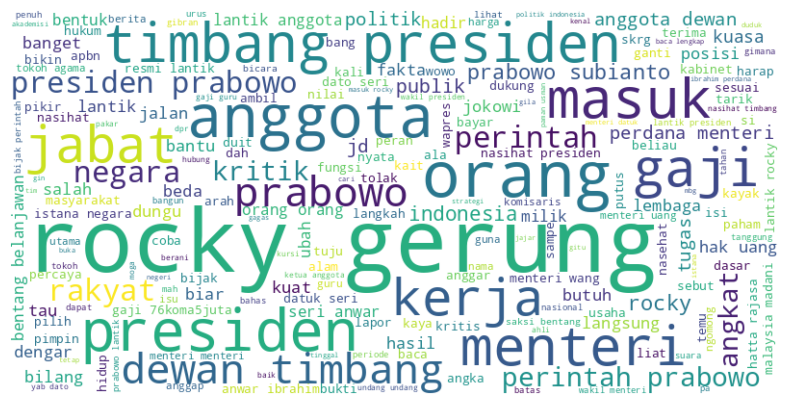

In [333]:
corpus = " ".join(df_bow["tokens_stemmed"].to_list())

# Buat Word Cloud
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white",
    colormap="viridis"
).generate(corpus)

# Tampilkan
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()


pertahankan kata:
pertimbangan 

## Word Embeddings (Representasi Berbasis Deep Learning)
Mengubah kata atau teks menjadi vektor padat (dense vectors) yang mampu menangkap makna semantik dan hubungan antar kata (contoh: Word2Vec, GloVe, FastText).
